# All-dataset metrics: simplified boxplots

This notebook compares a dataset-specific Syndri fixed-removal condition with raw expression and SPLIT. Change `SYNDRI_TARGET_FRACTIONS` in the configuration cell to select the precomputed fraction used for each dataset.

Every plotted observation represents one tissue slice. Metrics with multiple cell-type comparisons are averaged within a slice before boxplots are calculated, preventing slices with more annotated subtypes from receiving more weight.


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

ROOT = Path("/work/magroup/skrieger/Syndri/data/datasets")

DATASET_TITLES = {
    "agingbrain_merfish": "Aging brain MERFISH",
    "brain_merfish": "Brain MERFISH",
    "nsclc_cosmx": "NSCLC CosMx",
    "breast_xenium": "Breast Xenium",
}
DATASET_ALIASES = {
    "agingbrain_merfish": "AM",  # Aging Brain MERFISH
    "brain_merfish": "BM",       # Brain MERFISH
    "nsclc_cosmx": "NC",         # NSCLC CosMx
    "breast_xenium": "BX",       # Breast Xenium
}
TCELL_DATASETS = {
    "breast_xenium": "Breast Xenium",
    "nsclc_cosmx": "NSCLC CosMx",
}

# Select exactly one of the fixed-removal Syndri conditions.
SYNDRI_TARGET_FRACTIONS = {
    "agingbrain_merfish": 0.10,
    "brain_merfish": 0.30,
    "nsclc_cosmx": 0.5,
    "breast_xenium": 0.30,
}
SYNDRI_LABEL = f"Syndri"
METHOD_ORDER = ["SPLIT",SYNDRI_LABEL]
COUNT_METHOD_ORDER = ["Raw", "SPLIT", SYNDRI_LABEL]
DELTA_PLOT_ORDER = ["SPLIT", SYNDRI_LABEL]
hex =  sns.color_palette('deep',n_colors=3).as_hex()
COLORS = {
    "Raw": hex[0],
    SYNDRI_LABEL: hex[1],
    "SPLIT": hex[2],
    # "Raw": "#8F8F8F",
    # SYNDRI_LABEL: "#2688BE",
    # "SPLIT": "#8260A8",
}

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.dpi": 130,
})

print(f"Selected Syndri method: {SYNDRI_LABEL}")

Selected Syndri method: Syndri


In [3]:
def load_per_slice_csv(dataset, family, filename, usecols=None):
    """Load one result file per slice and attach dataset/slice provenance."""
    frames = []
    root = ROOT / dataset / "results" / "metrics" / family
    for path in sorted(root.glob(f"*/{filename}")):
        if path.stat().st_size == 0:
            continue
        try:
            frame = pd.read_csv(path, usecols=usecols, low_memory=False)
        except pd.errors.EmptyDataError:
            continue
        frame["dataset"] = dataset
        frame["slice"] = path.parent.name
        frames.append(frame)
    return pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()


def valid_rows(frame):
    result = frame.copy()
    if "error" in result:
        result = result.loc[result["error"].fillna("").astype(str).eq("")].copy()
    return result


def fixed_syndri_mask(frame, condition_col):
    fraction = pd.to_numeric(
        frame.get("target_removed_fraction"), errors="coerce"
    )
    target = frame["dataset"].map(SYNDRI_TARGET_FRACTIONS)

    return (
        frame[condition_col].astype(str).str.startswith(
            "cleaned_admixed_removed_frac_", na=False
        )
        & np.isclose(fraction, target, rtol=0, atol=1e-8)
    )


def boxplot_with_points(
    ax, data, x, y, order, palette, ylabel="", zero_line=False
):
    sns.boxplot(
        data=data, x=x, y=y, hue=x, order=order, hue_order=order,
        palette=palette, legend=False, width=0.58, showfliers=False,
        linewidth=1.1, ax=ax,
    )
    sns.stripplot(
        data=data, x=x, y=y, order=order, color="#222222",
        alpha=0.55, size=3.5, jitter=0.13, ax=ax,
    )
    if zero_line:
        ax.axhline(0, color="#666666", linestyle="--", linewidth=1)
    ax.set_xlabel("")
    ax.set_ylabel(ylabel)
    ax.grid(axis="y", alpha=0.22)


def add_n_labels(ax, data, category_col, order):
    ymax = ax.get_ylim()[1]
    ymin = ax.get_ylim()[0]
    y = ymax - 0.04 * (ymax - ymin)
    for position, category in enumerate(order):
        n = data.loc[data[category_col].eq(category), "slice"].nunique()
        ax.text(position, y, f"n={n}", ha="center", va="top", fontsize=8)


## Non-T-cell clustering metrics

The first figure shows each metric on its original scale for raw, Syndri, and SPLIT. The second uses paired slices and orients deltas so positive always means improvement over raw expression. Metrics are ordered by Syndri's mean percentage-point advantage over SPLIT, averaging matched slices within each dataset and then averaging datasets equally. CH = Calinski–Harabasz; DB = Davies–Bouldin; NMI = Leiden NMI; ARI = Leiden ARI.


In [4]:
non_tcell_frames = []
for dataset in DATASET_TITLES:
    frame = load_per_slice_csv(dataset, "non_tcell", "non_tcell_metrics.csv")
    if not frame.empty:
        non_tcell_frames.append(frame)

if not non_tcell_frames:
    raise FileNotFoundError("No non_tcell_metrics.csv files were found.")

non_tcell = valid_rows(pd.concat(non_tcell_frames, ignore_index=True))
non_tcell["target_removed_fraction"] = pd.to_numeric(
    non_tcell.get("target_removed_fraction"), errors="coerce"
)
non_tcell["method"] = np.select(
    [
        non_tcell["case"].eq("admixed"),
        fixed_syndri_mask(non_tcell, "case"),
        non_tcell["case"].eq("SPLIT"),
    ],
    ["Raw", SYNDRI_LABEL, "SPLIT"],
    default="",
)
non_tcell = non_tcell.loc[non_tcell["method"].ne("")].copy()

NON_TCELL_METRICS = {
    "silhouette_score": ("Sil", 1),
    "calinski_harabasz": ("CH", 1),
    "davies_bouldin": ("DB", -1),
    "leiden_nmi_vs_label": ("NMI", 1),
    "leiden_adjusted_rand_vs_label": ("ARI", 1),
}

original_rows = []
for metric, (label, _) in NON_TCELL_METRICS.items():
    values = (
        non_tcell.groupby(["dataset", "slice", "method"], observed=True)[metric]
        .mean().rename("value").reset_index()
    )
    original_rows.append(values.assign(metric=label))
non_tcell_original = (
    pd.concat(original_rows, ignore_index=True).dropna(subset=["value"])
)

rows = []
percent_rows = []
for metric, (label, direction) in NON_TCELL_METRICS.items():
    values = non_tcell.pivot_table(
        index=["dataset", "slice"], columns="method", values=metric, aggfunc="mean"
    )
    if "Raw" not in values:
        continue
    for method in METHOD_ORDER:
        if method not in values:
            continue
        improvement = (values[method] - values["Raw"]) * direction
        rows.append(improvement.rename("improvement").reset_index().assign(
            method=method, metric=label
        ))
        raw = values["Raw"].replace(0, np.nan)
        percent_change = 100 * direction * (values[method] - raw) / raw
        percent_rows.append(
            percent_change.rename("percent_change").reset_index().assign(
                method=method, metric=label
            )
        )

non_tcell_plot = pd.concat(rows, ignore_index=True).dropna(subset=["improvement"])
non_tcell_percent = (
    pd.concat(percent_rows, ignore_index=True)
    .replace([np.inf, -np.inf], np.nan)
    .dropna(subset=["percent_change"])
)
# Rank metrics by Syndri's advantage over SPLIT on matched slices.
# Average within dataset first so each dataset contributes equally.
paired_percent = non_tcell_percent.pivot_table(
    index=["dataset", "slice", "metric"], columns="method",
    values="percent_change", aggfunc="mean",
)
paired_percent = paired_percent.dropna(subset=METHOD_ORDER)
metric_advantage = (
    (paired_percent[SYNDRI_LABEL] - paired_percent["SPLIT"])
    .groupby(level=["dataset", "metric"]).mean()
    .groupby(level="metric").mean()
)
metric_order = (
    metric_advantage.reindex([label for label, _ in NON_TCELL_METRICS.values()])
    .sort_values(ascending=False, kind="stable").index.tolist()
)
print(non_tcell_plot.groupby(["dataset", "method"])["slice"].nunique())


dataset             method
agingbrain_merfish  SPLIT     12
                    Syndri    12
brain_merfish       SPLIT      3
                    Syndri     3
breast_xenium       SPLIT     19
                    Syndri    19
nsclc_cosmx         SPLIT      8
                    Syndri     8
Name: slice, dtype: int64


/tmp/ipykernel_1521444/3291649496.py:15: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(
/tmp/ipykernel_1521444/3291649496.py:15: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(
/tmp/ipykernel_1521444/3291649496.py:15: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(
/tmp/ipykernel_1521444/3291649496.py:15: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(
/tmp/ipykernel_1521444/3291649496.py:15: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='da

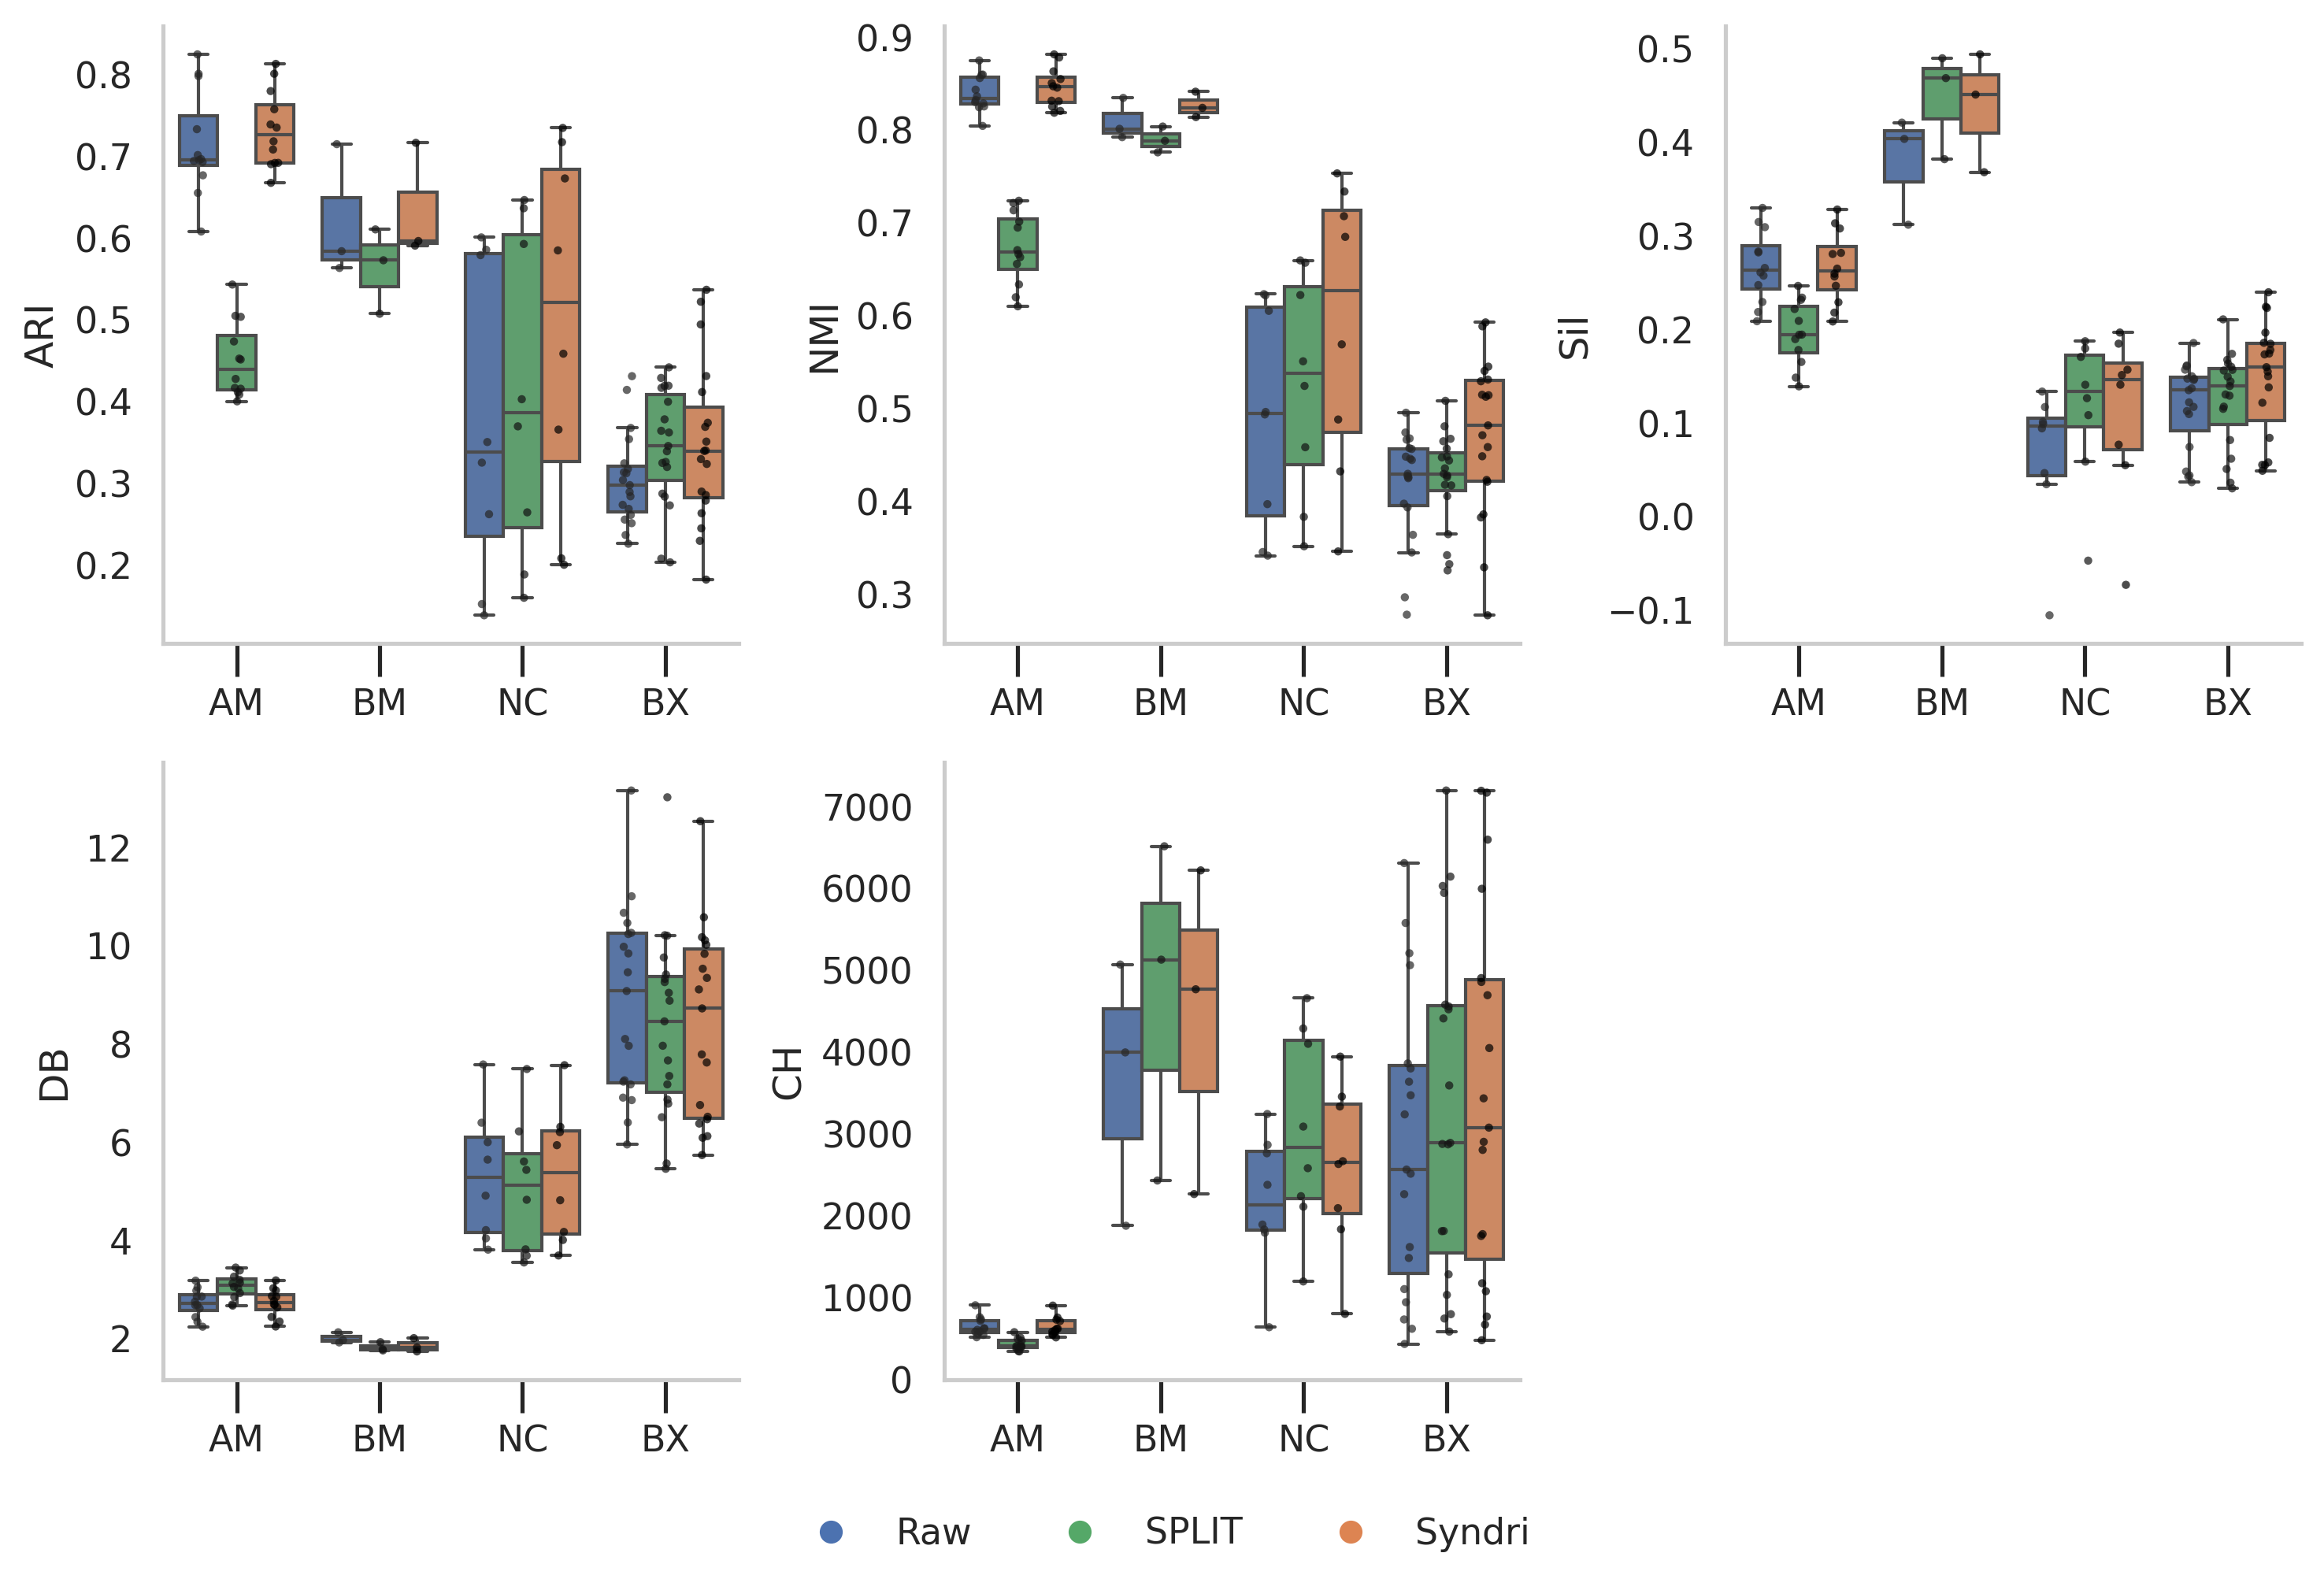

In [7]:
# One multi-panel swarm figure: metrics are panels and datasets are x groups.
swarm_data = non_tcell_original.copy()
swarm_data["dataset_alias"] = swarm_data["dataset"].map(DATASET_ALIASES)
dataset_order = list(DATASET_ALIASES.values())

fig, axes = plt.subplots(2, 3, figsize=(10, 7), squeeze=False,dpi=300)
for ax, metric in zip(axes.flat, metric_order):
    subset = swarm_data.loc[swarm_data["metric"].eq(metric)]
    sns.boxplot(
            data=subset, x="dataset_alias", y="value", hue="method",
            order=dataset_order, hue_order=COUNT_METHOD_ORDER, dodge=True,
            palette=COLORS, legend=False, ax=ax,showfliers=False
        )
    
    sns.stripplot(
        data=subset, x="dataset_alias", y="value", hue="method",
        order=dataset_order, hue_order=COUNT_METHOD_ORDER, dodge=True,
        color='black', size=2.5, alpha=0.7, legend=False, ax=ax,jitter=True,
        # edgecolor='black',linewidth=1
    )


    # ax.set_title(metric, fontsize=11, pad=10)
    ax.set_xlabel("")
    ax.set_ylabel(metric)
    ax.tick_params(
        axis="x", top=False, labeltop=False, bottom=True, labelbottom=True, size=10
    )
    ax.grid(axis="x", visible=False)
    ax.grid(axis="y", visible=False)
    ax.margins(x=0.03)

for ax in axes.flat[len(metric_order):]:
    ax.remove()

legend_handles = [
    plt.Line2D(
        [0], [0], marker="o", linestyle="", markersize=6,
        markerfacecolor=COLORS[method], markeredgecolor=COLORS[method],
        label=method,
    )
    for method in COUNT_METHOD_ORDER
]
fig.legend(
    handles=legend_handles, loc="lower center", ncol=3,
    bbox_to_anchor=(0.5, 0.01), frameon=False,
)
# fig.suptitle("Cell-type separation metrics", fontsize=15, fontweight="bold", y=1.01)
fig.tight_layout(rect=[0, 0.06, 1, 0.98], h_pad=1.0, w_pad=0.8)
plt.show()

In [24]:
print(COLORS)

{'Raw': '#4c72b0', 'Syndri': '#dd8452', 'SPLIT': '#55a868'}


### Cell-type separation: paired change from Raw

Each observation is one tissue slice with Raw, SPLIT, and Syndri available. The dashed line marks the slice-level Raw baseline at zero; positive change indicates improvement (Davies–Bouldin is reversed).


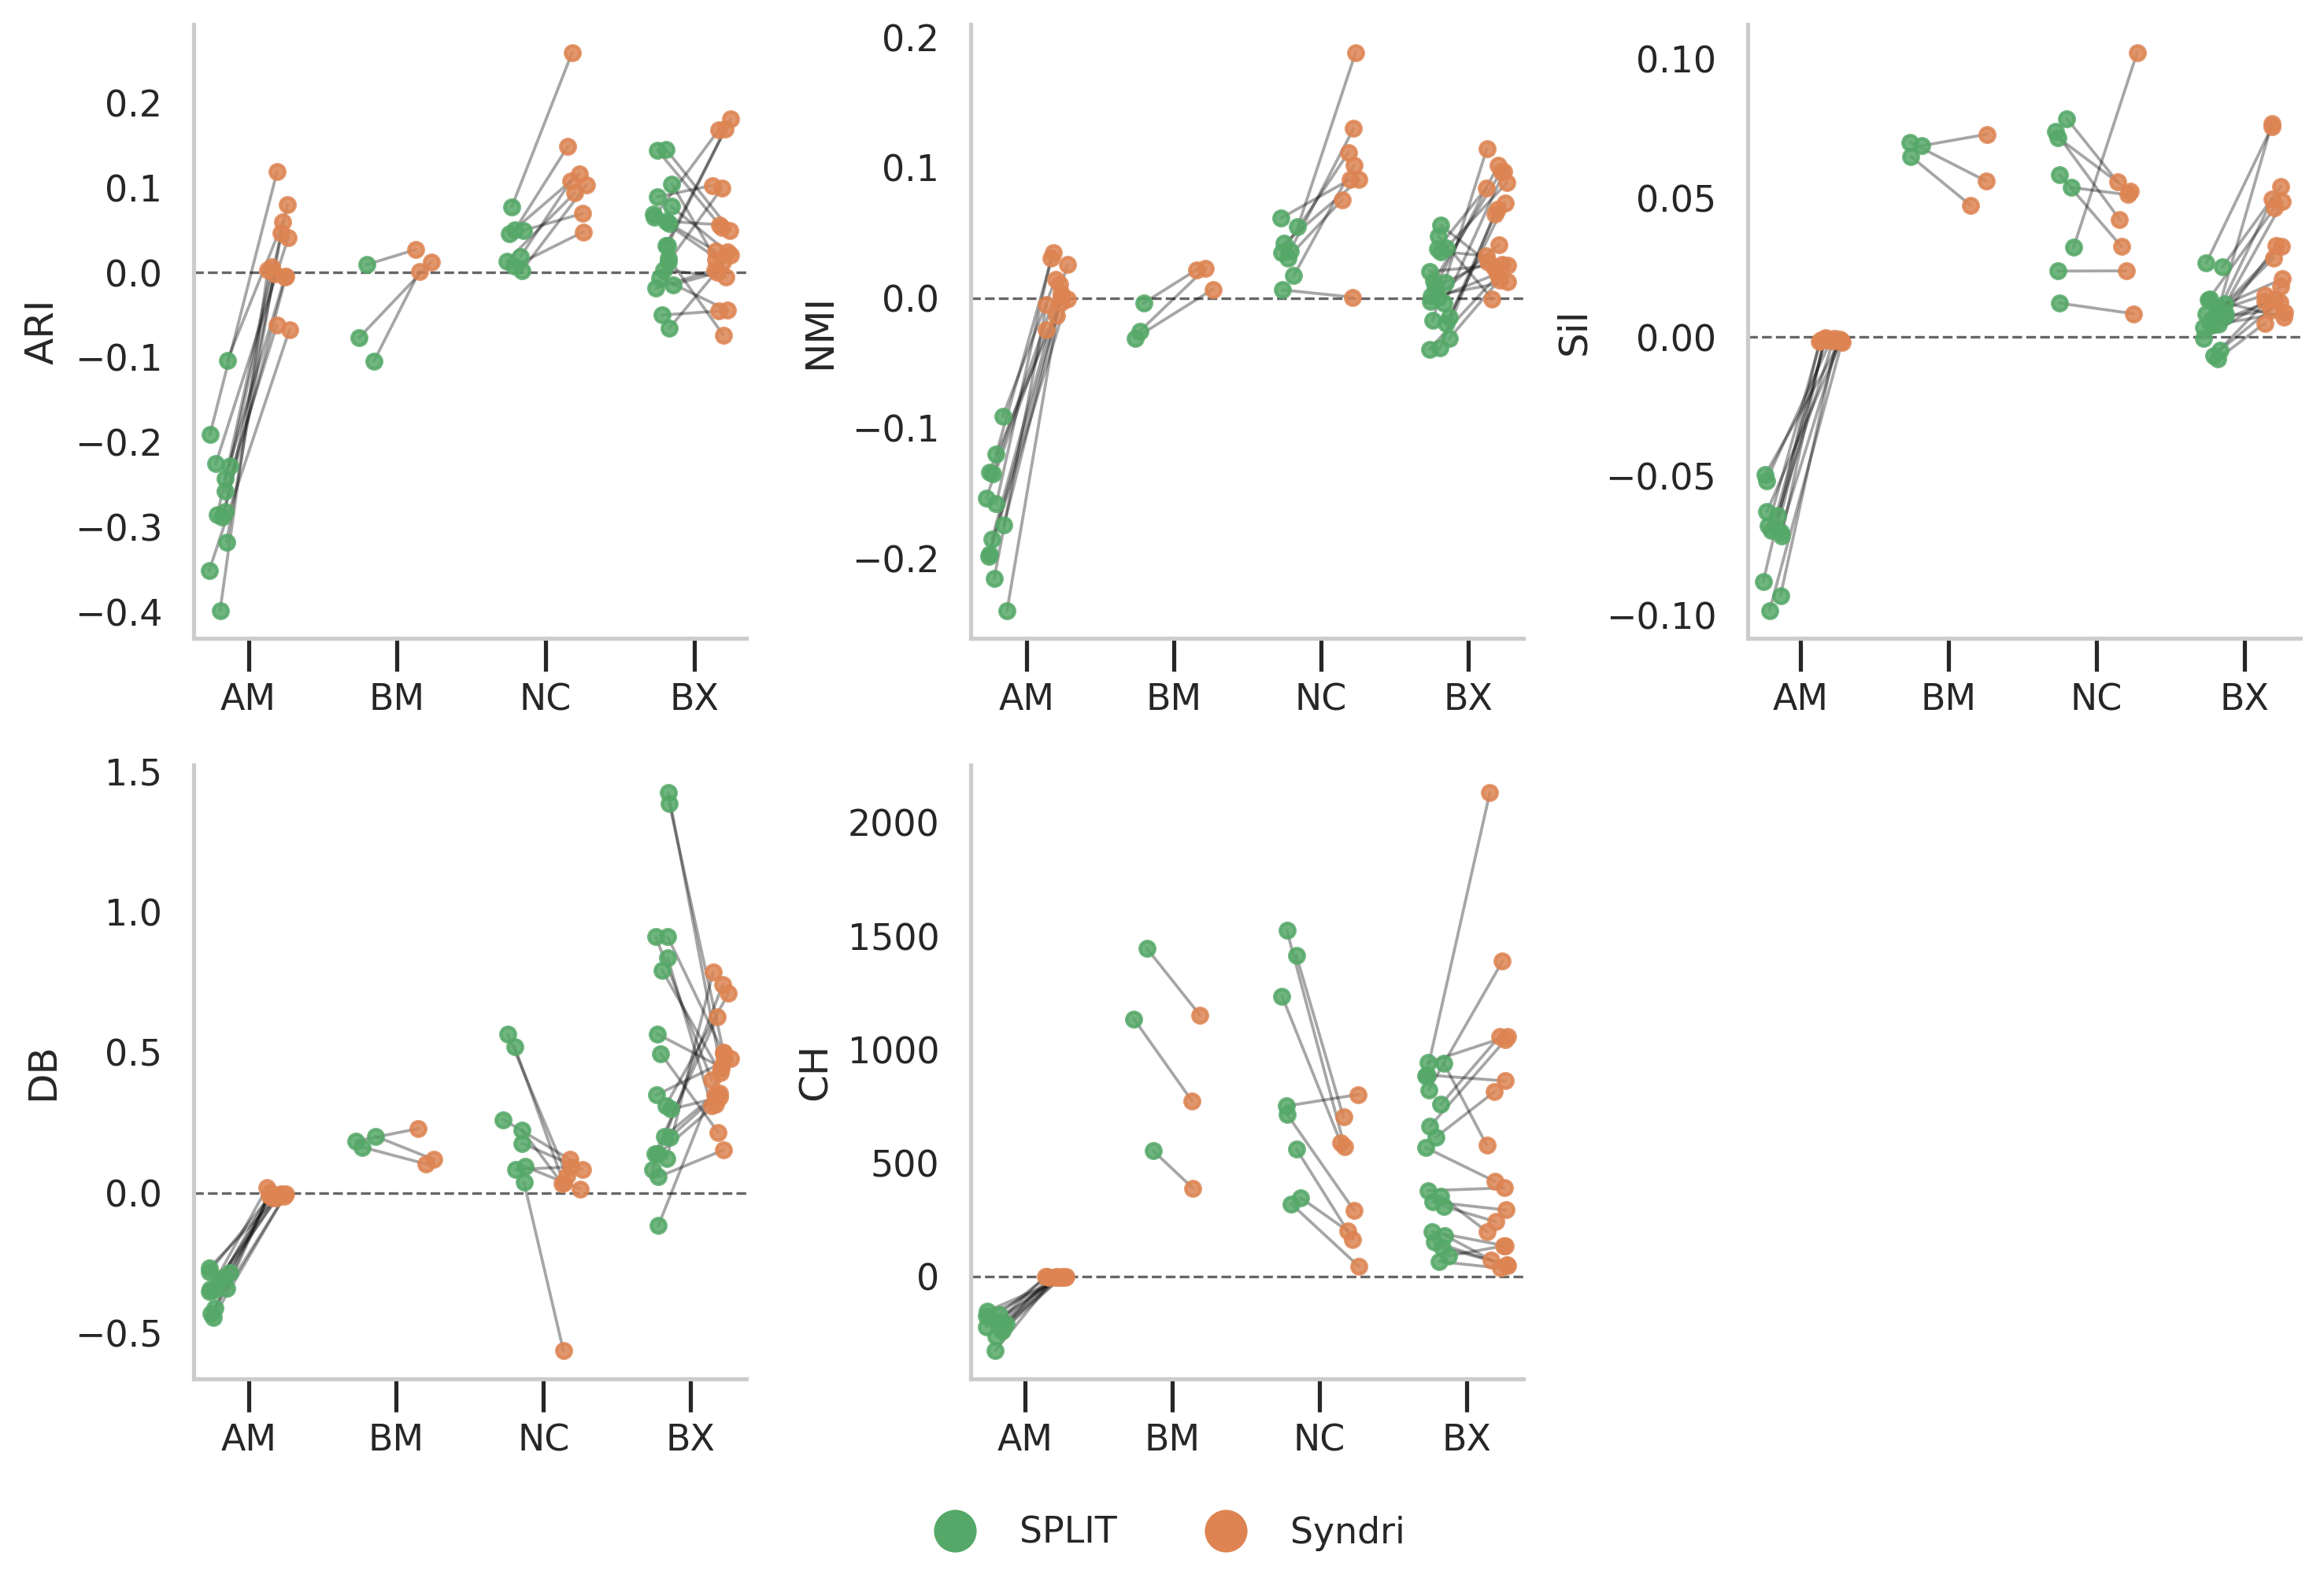

In [35]:
# Keep the same slices for both cleaned methods.
paired_deltas = non_tcell_plot.pivot_table(
    index=["dataset", "slice", "metric"], columns="method",
    values="improvement", aggfunc="mean",
).dropna(subset=DELTA_PLOT_ORDER).copy()
paired_delta_rows = paired_deltas[DELTA_PLOT_ORDER].reset_index()
delta_box_data = (
    paired_delta_rows.melt(
        id_vars=["dataset", "slice", "metric"],
        value_vars=DELTA_PLOT_ORDER,
        var_name="method", value_name="delta",
    )
)
delta_box_data["dataset_alias"] = delta_box_data["dataset"].map(DATASET_ALIASES)

rng = np.random.default_rng(42)
method_offsets = (
    np.arange(len(DELTA_PLOT_ORDER)) - (len(DELTA_PLOT_ORDER) - 1) / 2
) * (0.8 / len(DELTA_PLOT_ORDER))
fig, axes = plt.subplots(2, 3, figsize=(10, 7), squeeze=False, dpi=300)
for ax, metric in zip(axes.flat, metric_order):
    subset = delta_box_data.loc[delta_box_data["metric"].eq(metric)]
    # sns.boxplot(
    #     data=subset, x="dataset_alias", y="delta", hue="method",
    #     order=dataset_order, hue_order=DELTA_PLOT_ORDER, dodge=True,
    #     palette=COLORS, legend=False, ax=ax, showfliers=False,
    # )
    for dataset_pos, dataset in enumerate(DATASET_TITLES):
        paired = paired_delta_rows.loc[
            paired_delta_rows["dataset"].eq(dataset)
            & paired_delta_rows["metric"].eq(metric),
            DELTA_PLOT_ORDER,
        ]
        if paired.empty:
            continue
        y_positions = paired.to_numpy()
        x_positions = (
            dataset_pos + method_offsets
            + rng.uniform(-0.08, 0.08, size=y_positions.shape)
        )
        for x, y in zip(x_positions, y_positions):
            ax.plot(x, y, color="0", linewidth=0.9, alpha=0.35, zorder=2.5)
        for method_pos in range(len(DELTA_PLOT_ORDER)):
            ax.scatter(
                x_positions[:, method_pos], y_positions[:, method_pos],
                s=4.5**2, color=COLORS[METHOD_ORDER[method_pos]], alpha=0.85, zorder=3,
            )
    ax.axhline(0, color="#666666", linestyle="--", linewidth=0.8, zorder=0)
    ax.set_xlabel("")
    ax.set_ylabel(f"{metric}")
    ax.set_xticks(range(len(dataset_order)), labels=dataset_order)
    ax.tick_params(
        axis="x", top=False, labeltop=False, bottom=True, labelbottom=True, size=10
    )

    ax.grid(axis="x", visible=False)
    ax.grid(axis="y", visible=False)
    ax.margins(x=0.03)

for ax in axes.flat[len(metric_order):]:
    ax.remove()

legend_handles = [
    plt.Line2D(
        [0], [0], marker="o", linestyle="", markersize=12,
        markerfacecolor=COLORS[method], markeredgecolor=COLORS[method],
        label=method,
    )
    for method in DELTA_PLOT_ORDER
]
fig.legend(
    handles=legend_handles, loc="lower center", ncol=3,
    bbox_to_anchor=(0.5, 0.01), frameon=False,
)
fig.tight_layout(rect=[0, 0.06, 1, 0.98], h_pad=1.0, w_pad=0.8)
plt.show()

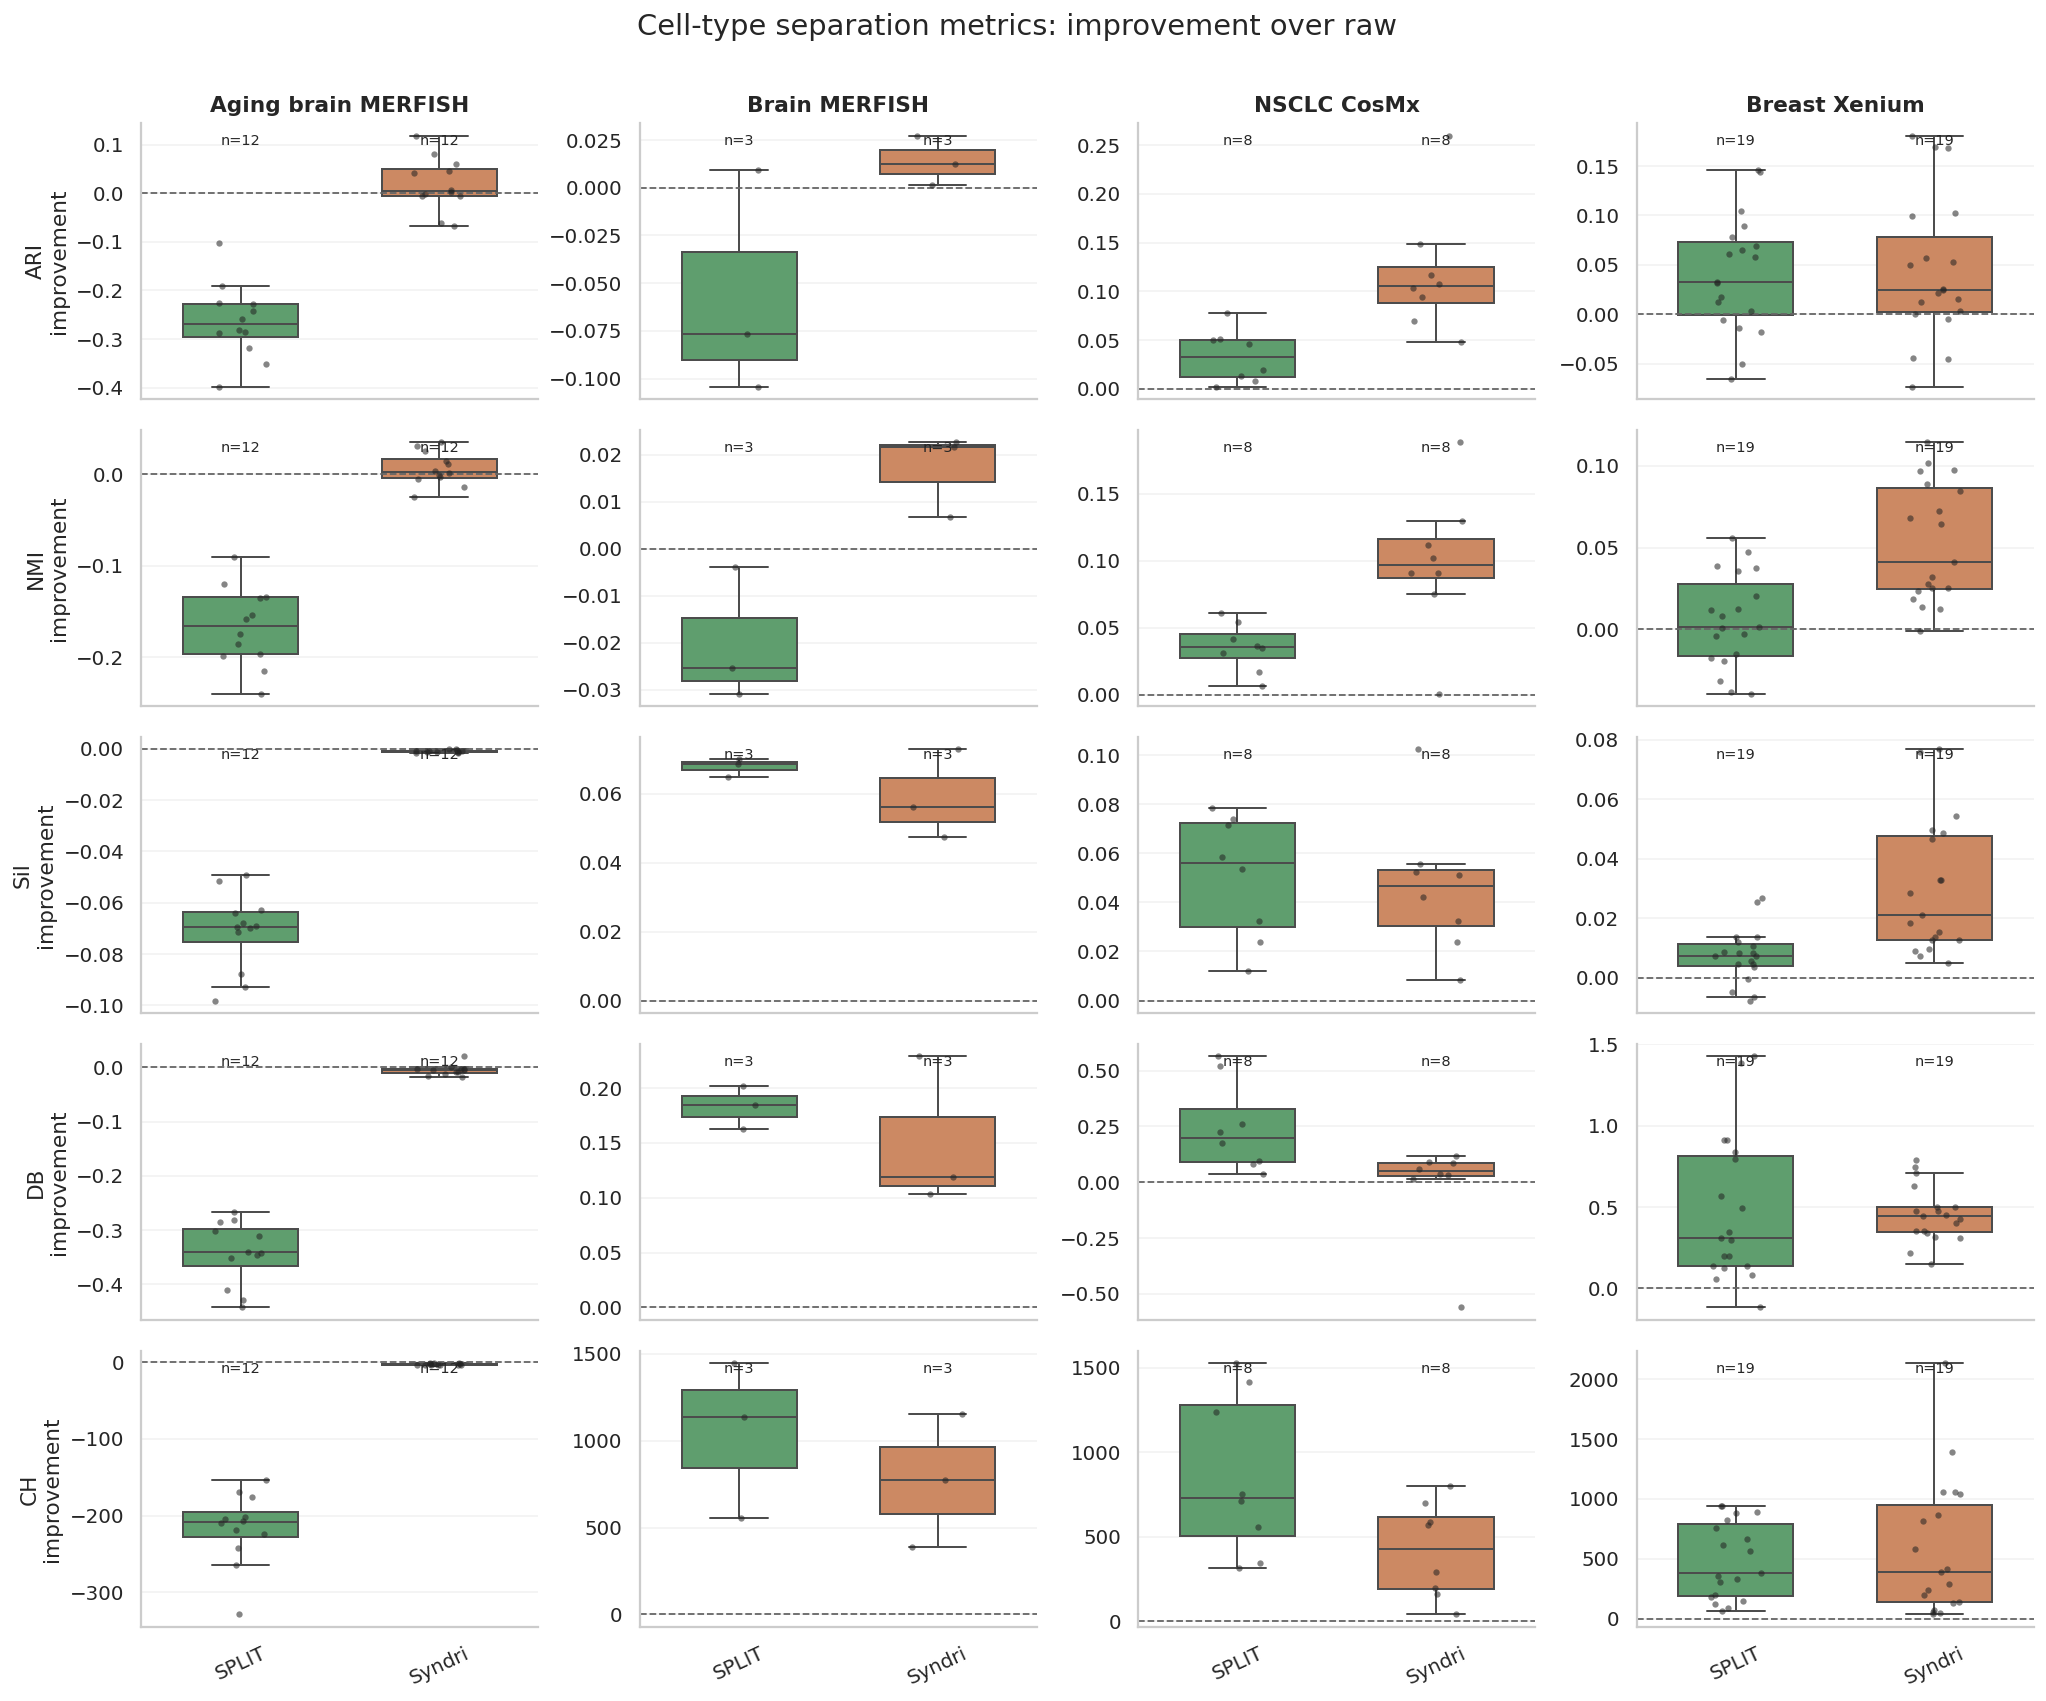

In [9]:
fig, axes = plt.subplots(
    len(metric_order), len(DATASET_TITLES),
    figsize=(4 * len(DATASET_TITLES), 2.6 * len(metric_order)),
    sharex=True, squeeze=False,
)

for col, (dataset, title) in enumerate(DATASET_TITLES.items()):
    for row, metric in enumerate(metric_order):
        ax = axes[row, col]
        subset = non_tcell_plot.loc[
            non_tcell_plot["dataset"].eq(dataset)
            & non_tcell_plot["metric"].eq(metric)
        ]
        boxplot_with_points(
            ax, subset, "method", "improvement", DELTA_PLOT_ORDER, COLORS,
            ylabel=f"{metric}\nimprovement" if col == 0 else "", zero_line=True,
        )
        add_n_labels(ax, subset, "method", DELTA_PLOT_ORDER)
        if row == 0:
            ax.set_title(title, fontweight="bold")
        if row < len(metric_order) - 1:
            ax.tick_params(axis="x", labelbottom=False)
        else:
            ax.tick_params(axis="x", rotation=25)

fig.suptitle("Cell-type separation metrics: improvement over raw", fontsize=16, y=1.005)
fig.tight_layout()
plt.show()




/tmp/ipykernel_1521444/1743479255.py:16: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  heatmap_annotations = heatmap_data.applymap(


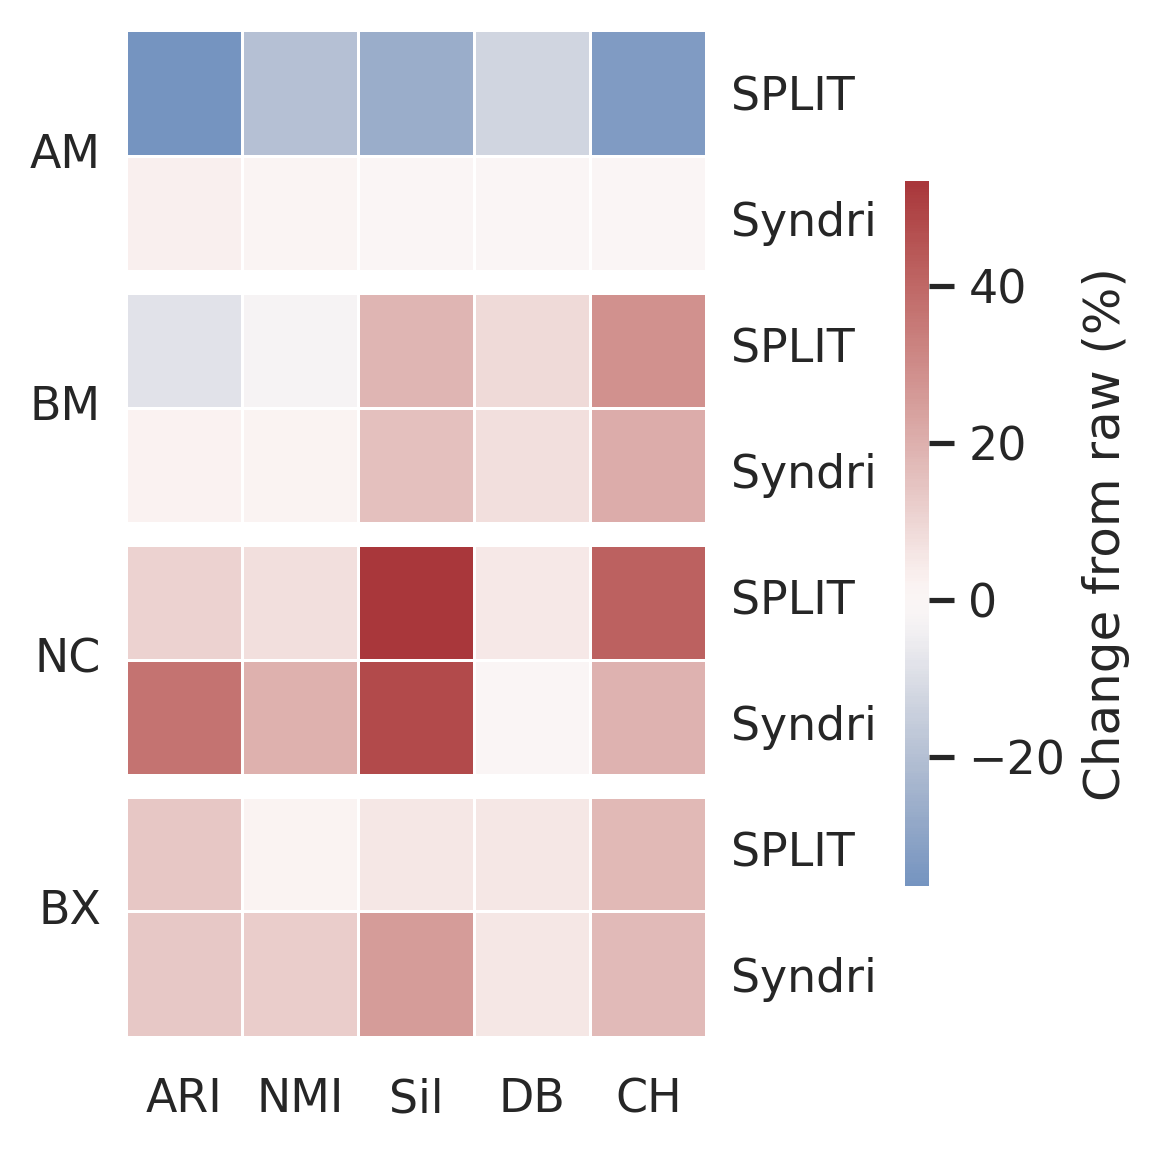

In [10]:
# Mean paired percent change across slices. Positive always indicates improvement.
heatmap_data = (
    non_tcell_percent.groupby(["dataset", "method", "metric"], observed=True)
    ["percent_change"].mean().unstack("metric")
)
heatmap_index = pd.MultiIndex.from_product(
    [DATASET_TITLES, METHOD_ORDER], names=["dataset", "method"]
)
heatmap_data = heatmap_data.reindex(index=heatmap_index, columns=metric_order)
dataset_ticks = (
    np.arange(len(DATASET_TITLES)) * len(METHOD_ORDER)
    + len(METHOD_ORDER) / 2
)
dataset_labels = [DATASET_ALIASES[dataset] for dataset in DATASET_TITLES]
method_labels = heatmap_data.index.get_level_values("method")
heatmap_annotations = heatmap_data.applymap(
    lambda value: f"{value:.1f}" if pd.notna(value) else ""
)

fig, ax = plt.subplots(figsize=(4, 4), dpi=300)
sns.heatmap(
    heatmap_data, cmap="vlag", center=0, fmt="",
    linewidths=0.7, linecolor="white", annot_kws={"fontsize": 9},
    cbar_kws={
        "orientation": "vertical", "location":"right", "label": "Change from raw (%)",
        "pad": 0.24, "fraction": 0.06, "aspect": 30,"shrink":0.7,
    },
    ax=ax
)
# A narrow white divider separates each two-row dataset group.
for boundary in range(len(METHOD_ORDER), len(heatmap_data), len(METHOD_ORDER)):
    ax.axhline(boundary, color="white", linewidth=6, zorder=10)
ax.set_yticks(dataset_ticks, labels=dataset_labels, rotation=0)
ax.tick_params(axis="y", length=0, pad=6)
ax.xaxis.tick_top()
ax.tick_params(axis="x", top=False, bottom=False, labeltop=False, labelbottom=True)
method_axis = ax.secondary_yaxis("right")
method_axis.set_yticks(np.arange(len(heatmap_data)) + 0.5, labels=method_labels)
method_axis.tick_params(axis="y", length=0, pad=6)
method_axis.spines["right"].set_visible(False)
ax.set_xlabel("")
ax.set_ylabel("")
# ax.set_title("Cell-type separation: percent change from raw", fontweight="bold")
fig.tight_layout()
plt.show()

### Syndri versus the best alternative

Each value is Syndri's signed percentage change from Raw minus the better of Raw (0%) and SPLIT on the same slice. Values are averaged across slices within each dataset; positive favors Syndri.


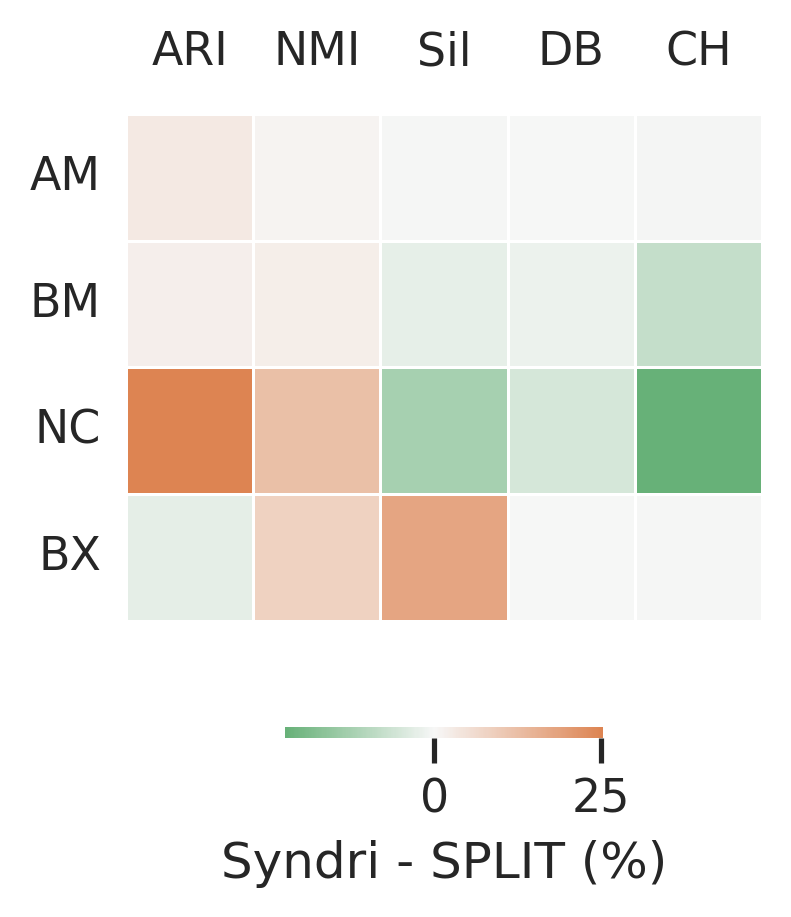

In [11]:
from matplotlib.colors import LinearSegmentedColormap

# paired_percent contains only slices with both Syndri and SPLIT.
best_alternative = paired_percent["SPLIT"].clip(lower=0)  # Raw = 0%
syndri_vs_best = (paired_percent[SYNDRI_LABEL] - best_alternative).rename(
    "advantage_percent"
)
syndri_best_heatmap = (
    syndri_vs_best.groupby(level=["dataset", "metric"]).mean()
    .unstack("metric")
    .reindex(index=DATASET_TITLES, columns=metric_order)
)
syndri_split_cmap = LinearSegmentedColormap.from_list(
    "syndri_split",
    [
        hex[2],  # SPLIT better
        "#F7F7F7",
        hex[1],  # Syndri better
    ]
)
#  "Raw": "#777777",
#     SYNDRI_LABEL: "#0072B2",
#     "SPLIT": "#6A3D9A"
fig, ax = plt.subplots(figsize=(2.8, 3.2), dpi=300)
sns.heatmap(
    syndri_best_heatmap, cmap=syndri_split_cmap, center=0, annot=False, fmt=".1f",
    linewidths=0.7, linecolor="white", annot_kws={"fontsize": 9},
    cbar_kws={
        "orientation": "horizontal",
        "label": "Syndri - SPLIT (%)",
        "pad": 0.16, "fraction": 0.08, "aspect": 30,"shrink":0.5
    },
    ax=ax,
)
ax.set_yticklabels(
    [DATASET_ALIASES[dataset] for dataset in syndri_best_heatmap.index],
    rotation=0,
)
ax.tick_params(axis="y", length=0, pad=6)
ax.xaxis.tick_top()
ax.tick_params(axis="x", top=False, bottom=False, labeltop=True, labelbottom=False)
ax.set_xlabel("")
ax.set_ylabel("")
# ax.set_title("Syndri vs best of Raw and SPLIT", fontsize=11, pad=12)
fig.tight_layout()
plt.show()

## T-cell metrics

Original values and paired improvements are averaged across eligible T-cell subtype comparisons within each tissue slice, so every boxplot observation is one slice.


In [12]:
def load_tcell(filename):
    frames = []
    for dataset in TCELL_DATASETS:
        frame = load_per_slice_csv(dataset, "tcell", filename)
        if not frame.empty:
            frames.append(frame)
    return valid_rows(pd.concat(frames, ignore_index=True)) if frames else pd.DataFrame()


def paired_tcell_improvement(frame, value_col, pair_cols, direction):
    data = frame.copy()
    data["target_removed_fraction"] = pd.to_numeric(
        data.get("target_removed_fraction"), errors="coerce"
    )
    data[value_col] = pd.to_numeric(data[value_col], errors="coerce")
    data = data.loc[np.isfinite(data[value_col])].copy()
    data["method"] = np.select(
        [
            data["condition"].eq("raw_X"),
            fixed_syndri_mask(data, "condition"),
            data["condition"].eq("SPLIT"),
        ],
        ["Raw", SYNDRI_LABEL, "SPLIT"],
        default="",
    )
    data = data.loc[data["method"].ne("")]
    values = data.pivot_table(
        index=["dataset", "slice", *pair_cols],
        columns="method", values=value_col, aggfunc="mean",
    )
    if "Raw" not in values:
        return pd.DataFrame()
    results = []
    for method in METHOD_ORDER:
        if method not in values:
            continue
        delta = ((values[method] - values["Raw"]) * direction).rename("improvement")
        results.append(delta.reset_index().assign(method=method))
    return pd.concat(results, ignore_index=True) if results else pd.DataFrame()


def tcell_original_scale(frame, value_col, metric):
    data = frame.copy()
    data["target_removed_fraction"] = pd.to_numeric(
        data.get("target_removed_fraction"), errors="coerce"
    )
    data[value_col] = pd.to_numeric(data[value_col], errors="coerce")
    data = data.loc[np.isfinite(data[value_col])].copy()
    data["method"] = np.select(
        [
            data["condition"].eq("raw_X"),
            fixed_syndri_mask(data, "condition"),
            data["condition"].eq("SPLIT"),
        ],
        ["Raw", SYNDRI_LABEL, "SPLIT"],
        default="",
    )
    return (
        data.loc[data["method"].ne("")]
        .groupby(["dataset", "slice", "method"], observed=True)[value_col]
        .mean().rename("value").reset_index().assign(metric=metric)
    )

cosine = load_tcell("tcell_cosine_similarity.csv")
cosine = cosine[~cosine['tissue'].str.startswith('cosmx')]
contamination = load_tcell("tcell_contamination_metrics.csv")
contamination = contamination[~contamination['tissue'].str.startswith('cosmx')]
cosine_plot = paired_tcell_improvement(
    cosine, "cosine_similarity",
    ["spatial_cell_type", "reference_cell_type"], direction=1,
)
cosine_plot["metric"] = "Reference cosine similarity"

contamination_plot = paired_tcell_improvement(
    contamination, "marker_overlap_frac",
    ["target_cell_type_i", "contaminating_cell_type_j"], direction=-1,
)
contamination_plot["metric"] = "Reduced marker contamination"

tcell_plot = pd.concat([cosine_plot, contamination_plot], ignore_index=True)
tcell_slice_plot = (
    tcell_plot.groupby(["dataset", "slice", "method", "metric"], observed=True)
    ["improvement"].mean().reset_index()
)
tcell_original = pd.concat([
    tcell_original_scale(cosine, "cosine_similarity", "Reference cosine similarity"),
    tcell_original_scale(contamination, "marker_overlap_frac", "Marker overlap fraction"),
], ignore_index=True)
print(tcell_slice_plot.groupby(["dataset", "method"])["slice"].nunique())


dataset        method
breast_xenium  SPLIT     19
               Syndri    19
nsclc_cosmx    SPLIT      8
               Syndri     8
Name: slice, dtype: int64


/tmp/ipykernel_2605455/3799942819.py:17: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(
/tmp/ipykernel_2605455/3799942819.py:17: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(


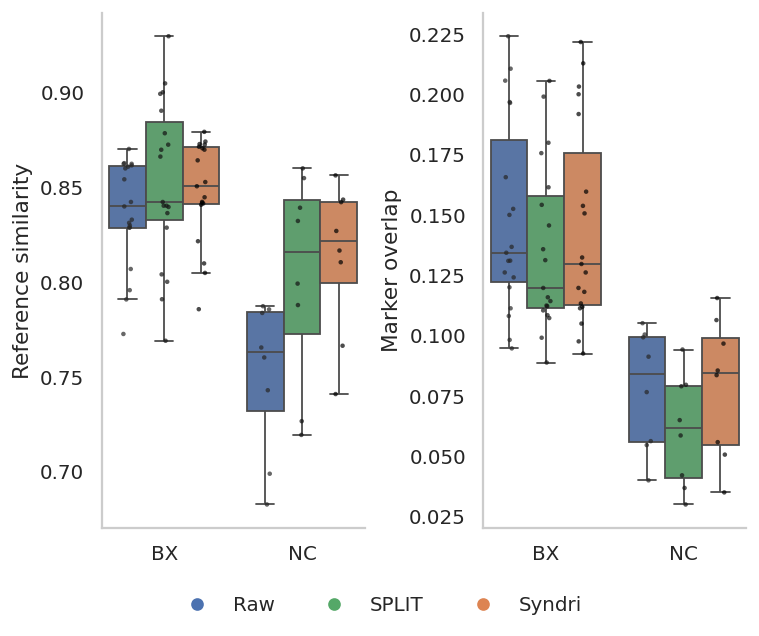

In [32]:
tcell_original_metric_order = [
    "Reference cosine similarity", "Marker overlap fraction",
]
ylabels = ["Reference similarity", "Marker overlap"]
tcell_dataset_order = [DATASET_ALIASES[dataset] for dataset in TCELL_DATASETS]
tcell_original_plot = tcell_original.assign(
    dataset_alias=tcell_original["dataset"].map(DATASET_ALIASES)
)
fig, axes = plt.subplots(1, len(tcell_original_metric_order), figsize=(6, 5), squeeze=False)
for i, (ax, metric) in enumerate(zip(axes.flat, tcell_original_metric_order)):
    subset = tcell_original_plot.loc[tcell_original_plot["metric"].eq(metric)]
    sns.boxplot(
        data=subset, x="dataset_alias", y="value", hue="method",
        order=tcell_dataset_order, hue_order=COUNT_METHOD_ORDER, dodge=True,
        palette=COLORS, legend=False, ax=ax, showfliers=False,
    )
    sns.stripplot(
        data=subset, x="dataset_alias", y="value", hue="method",
        order=tcell_dataset_order, hue_order=COUNT_METHOD_ORDER, dodge=True,
        color="black", size=2.5, alpha=0.7, legend=False, ax=ax, jitter=True,
    )
    ax.set(xlabel="", ylabel=ylabels[i])
    ax.grid(axis="x", visible=False)
    ax.grid(axis="y", visible=False)
    ax.margins(x=0.03)
fig.legend(handles=legend_handles, loc="lower center", ncol=3,
           bbox_to_anchor=(0.5, 0.01), frameon=False)
# fig.suptitle('T-cells')
fig.tight_layout(rect=[0, 0.08, 1, 1], w_pad=0.8)

plt.show()

/tmp/ipykernel_2605455/1075785178.py:13: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(
/tmp/ipykernel_2605455/1075785178.py:13: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(


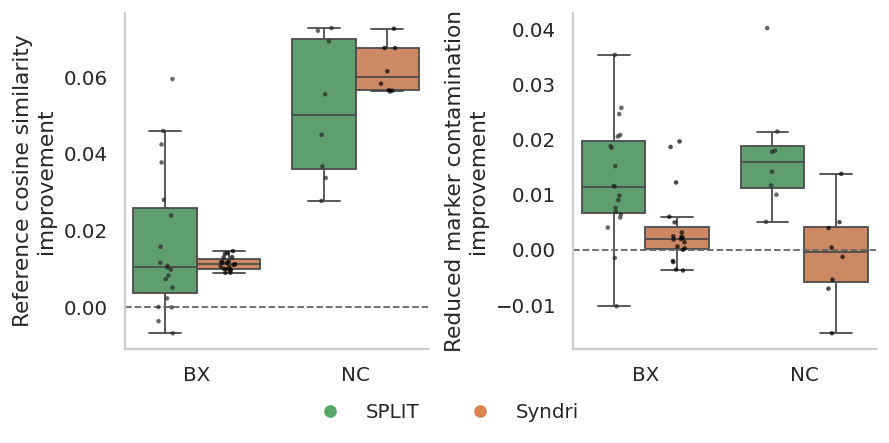

In [33]:
tcell_metric_order = ["Reference cosine similarity", "Reduced marker contamination"]
tcell_improvement_plot = tcell_slice_plot.assign(
    dataset_alias=tcell_slice_plot["dataset"].map(DATASET_ALIASES)
)
fig, axes = plt.subplots(1, len(tcell_metric_order), figsize=(7, 3.5), squeeze=False)
for ax, metric in zip(axes.flat, tcell_metric_order):
    subset = tcell_improvement_plot.loc[tcell_improvement_plot["metric"].eq(metric)]
    sns.boxplot(
        data=subset, x="dataset_alias", y="improvement", hue="method",
        order=tcell_dataset_order, hue_order=DELTA_PLOT_ORDER, dodge=True,
        palette=COLORS, legend=False, ax=ax, showfliers=False,
    )
    sns.stripplot(
        data=subset, x="dataset_alias", y="improvement", hue="method",
        order=tcell_dataset_order, hue_order=DELTA_PLOT_ORDER, dodge=True,
        color="black", size=2.5, alpha=0.7, legend=False, ax=ax, jitter=True,
    )
    ax.axhline(0, color="#666666", linestyle="--", linewidth=1)
    ax.set(xlabel="", ylabel=f"{metric}\nimprovement")
    ax.grid(axis="x", visible=False)
    ax.grid(axis="y", visible=False)
    ax.margins(x=0.03)
fig.legend(handles=legend_handles[1:], loc="lower center", ncol=2,
           bbox_to_anchor=(0.5, 0.01), frameon=False)
fig.tight_layout(rect=[0, 0.08, 1, 1], w_pad=0.8)
plt.show()


## Expression retained after cleaning

These are absolute per-slice count summaries rather than improvements from raw.


/tmp/ipykernel_1521444/3600030960.py:20: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(
/tmp/ipykernel_1521444/3600030960.py:20: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(


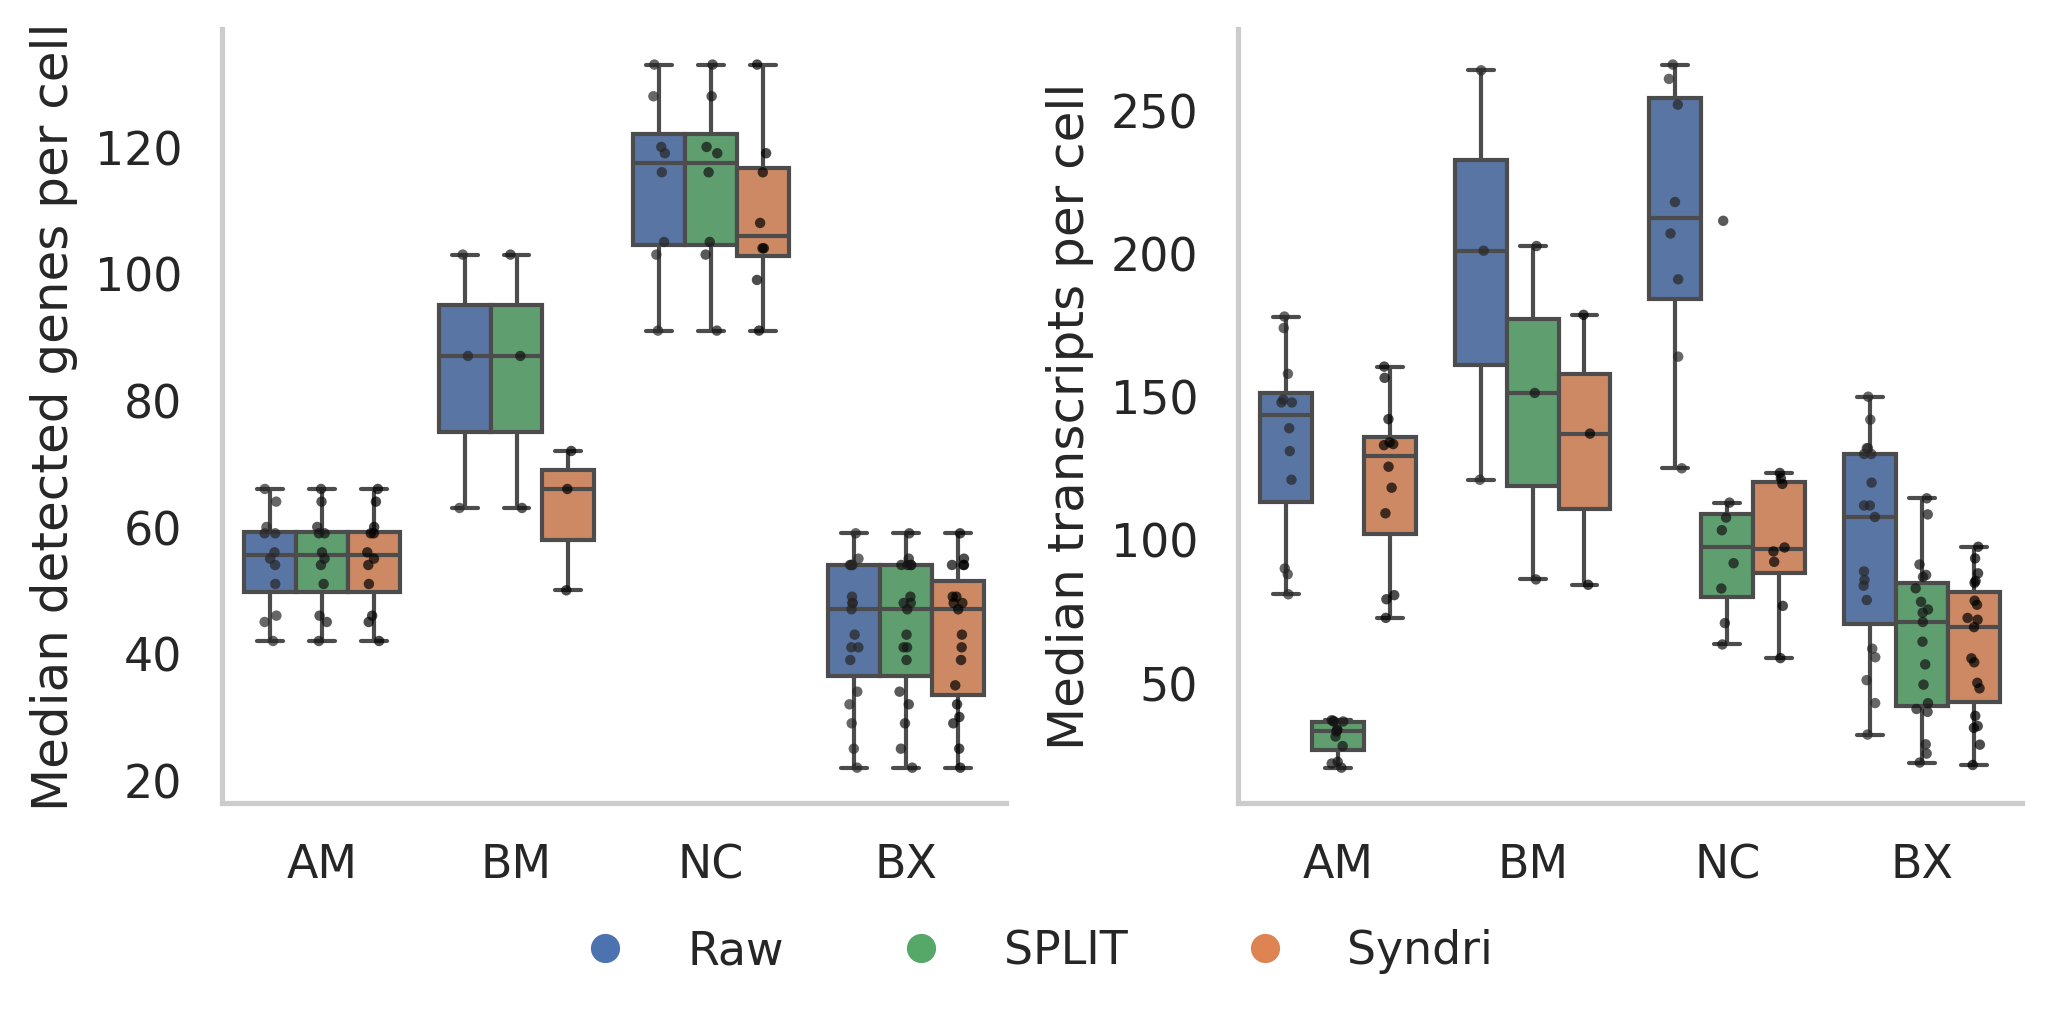

In [13]:
COUNT_METRICS = {
    "median_genes_per_cell": "Median detected genes per cell",
    "median_transcripts_per_cell": "Median transcripts per cell",
}
count_data = non_tcell.loc[
    non_tcell["method"].isin(COUNT_METHOD_ORDER),
    ["dataset", "slice", "method", *COUNT_METRICS],
].copy()

count_plot = count_data.assign(dataset_alias=count_data["dataset"].map(DATASET_ALIASES))
dataset_order = [DATASET_ALIASES[dataset] for dataset in DATASET_TITLES]
fig, axes = plt.subplots(1, len(COUNT_METRICS), figsize=(7, 3.5), squeeze=False,dpi=300)
for ax, (metric, label) in zip(axes.flat, COUNT_METRICS.items()):
    subset = count_plot.dropna(subset=[metric])
    sns.boxplot(
        data=subset, x="dataset_alias", y=metric, hue="method",
        order=dataset_order, hue_order=COUNT_METHOD_ORDER, dodge=True,
        palette=COLORS, legend=False, ax=ax, showfliers=False,
    )
    sns.stripplot(
        data=subset, x="dataset_alias", y=metric, hue="method",
        order=dataset_order, hue_order=COUNT_METHOD_ORDER, dodge=True,
        color="black", size=2.5, alpha=0.7, legend=False, ax=ax, jitter=True,
    )
    ax.set(xlabel="", ylabel=label)
    ax.grid(axis="x", visible=False)
    ax.grid(axis="y", visible=False)
    ax.margins(x=0.03)
fig.legend(handles=legend_handles, loc="lower center", ncol=3,
           bbox_to_anchor=(0.5, 0.01), frameon=False)
fig.tight_layout(rect=[0, 0.08, 1, 1], w_pad=0.8)
plt.show()


## Spatial admixture (`p_admix`)

Scores are paired by cell with raw expression, then summarized as one median improvement per slice. Positive values indicate a reduction in admixture score.


In [59]:
# p_admix_rows = []
# needed_columns = [
#     "source_file", "slice", "cell", "cell_type", "setting", "scores",
#     "removed_frac_target",
# ]

# for dataset in DATASET_TITLES:
#     root = ROOT / dataset / "results" / "metrics" / "admixture_scores"
#     for path in sorted(root.glob("*/admixture_scores.csv")):
#         try:
#             frame = pd.read_csv(path, usecols=lambda c: c in needed_columns, low_memory=False)
#         except pd.errors.EmptyDataError:
#             continue
#         if "slice" not in frame:
#             frame["slice"] = path.parent.name
#         frame["dataset"] = dataset
#         frame["scores"] = pd.to_numeric(frame["scores"], errors="coerce")
#         frame["removed_frac_target"] = pd.to_numeric(
#             frame.get("removed_frac_target"), errors="coerce"
#         )
#         raw = frame.loc[frame["setting"].eq("raw"), ["cell", "cell_type", "scores"]].rename(
#             columns={"scores": "raw_score"}
#         )
#         for method, mask in {
#             SYNDRI_LABEL: (
#                 frame["setting"].astype(str).str.startswith("syndri_remove_", na=False)
#                 & np.isclose(
#                     frame["removed_frac_target"],
#                     SYNDRI_TARGET_FRACTIONS[dataset],
#                     rtol=0,
#                     atol=1e-8,
#                 )),
#                 "SPLIT": frame["setting"].eq("SPLIT")
#                 }.items():
#             cleaned = frame.loc[mask, ["cell", "cell_type", "scores"]]
#             paired = cleaned.merge(raw, on=["cell", "cell_type"], how="inner", validate="many_to_one")
#             if paired.empty:
#                 continue
#             p_admix_rows.append({
#                 "dataset": dataset,
#                 "slice": path.parent.name,
#                 "method": method,
#                 "improvement": (paired["raw_score"] - paired["scores"]).median(),
#                 "n_cells": paired["cell"].nunique(),
#             })

# p_admix_plot = pd.DataFrame(p_admix_rows)
# print(p_admix_plot.groupby(["dataset", "method"])["slice"].nunique())

In [60]:
# fig, axes = plt.subplots(1, len(DATASET_TITLES), figsize=(15, 4.5), sharey=True)
# for ax, (dataset, title) in zip(np.atleast_1d(axes), DATASET_TITLES.items()):
#     subset = p_admix_plot.loc[p_admix_plot["dataset"].eq(dataset)]
#     boxplot_with_points(
#         ax, subset, "method", "improvement", DELTA_PLOT_ORDER, COLORS,
#         ylabel="Reduction in median admixture score" if ax is np.atleast_1d(axes)[0] else "",
#     )
#     add_n_labels(ax, subset, "method", DELTA_PLOT_ORDER)
#     ax.set_title(
#         f"{title}\nSyndri target: {SYNDRI_TARGET_FRACTIONS[dataset]:.0%}",
#         fontweight="bold",
#     )
#     ax.tick_params(axis="x", rotation=25)

# fig.suptitle("Spatial admixture scores: improvement over raw", fontsize=16, y=1.02)
# fig.tight_layout()
# plt.show()


## Optional export

Uncomment and adapt `fig.savefig(...)` in any plotting cell to export publication-resolution PNG or PDF files. The tables `non_tcell_plot`, `tcell_slice_plot`, `count_data`, and `p_admix_plot` contain the exact slice-level values shown in the figures.
